<a href="https://colab.research.google.com/github/AI-Darren-AI/ChatGPT-Review-Analysis/blob/main/ChatGPT_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
#Importing Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
from google.colab import files
uploaded = files.upload()


Saving chatgpt_reviews.csv to chatgpt_reviews.csv


In [4]:
df = pd.read_csv('chatgpt_reviews.csv')
df.head()

,Review Id,Review,Ratings,Review Date
0,6fb93778-651a-4ad1-b5ed-67dd0bd35aac,good,5,2024-08-23 19:30:05
1,81caeefd-3a28-4601-a898-72897ac906f5,good,5,2024-08-23 19:28:18
2,452af49e-1d8b-4b68-b1ac-a94c64cb1dd5,nice app,5,2024-08-23 19:22:59
3,372a4096-ee6a-4b94-b046-cef0b646c965,"nice, ig",5,2024-08-23 19:20:50
4,b0d66a4b-9bde-4b7c-8b11-66ed6ccdd7da,"this is a great app, the bot is so accurate to...",5,2024-08-23 19:20:39


In [5]:
print(df.shape)

#Checking for duplicate rows
print(df.duplicated().sum())

df = df.drop_duplicates()
print(df.duplicated().sum())


(196727, 4)
2511
0


In [6]:
# Looking for Null values

df.isnull().sum()

,0
Review Id,0
Review,6
Ratings,0
Review Date,0


In [7]:
df = df.dropna()

df.isnull().sum()

,0
Review Id,0
Review,0
Ratings,0
Review Date,0


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 194210 entries, 0 to 196726
Data columns (total 4 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   Review Id    194210 non-null  object
 1   Review       194210 non-null  object
 2   Ratings      194210 non-null  int64 
 3   Review Date  194210 non-null  object
dtypes: int64(1), object(3)
memory usage: 7.4+ MB


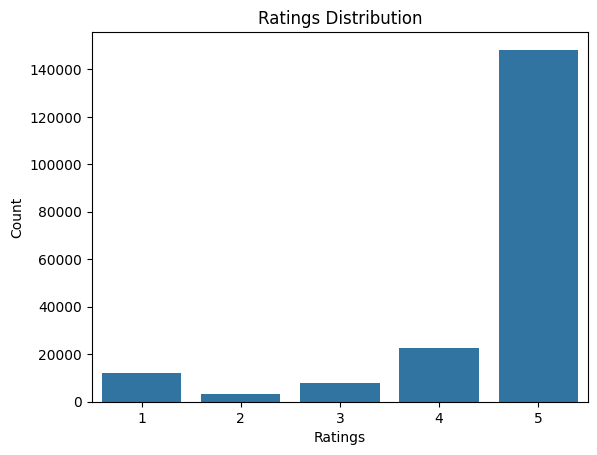

In [9]:
sns.countplot(data = df, x = 'Ratings')
plt.title('Ratings Distribution')
plt.ylabel('Count')
plt.show()


In [14]:
# Creation of month column from Dates.

df['Review Date'] = pd.to_datetime(df['Review Date'])
df['month'] = df['Review Date'].dt.month_name()

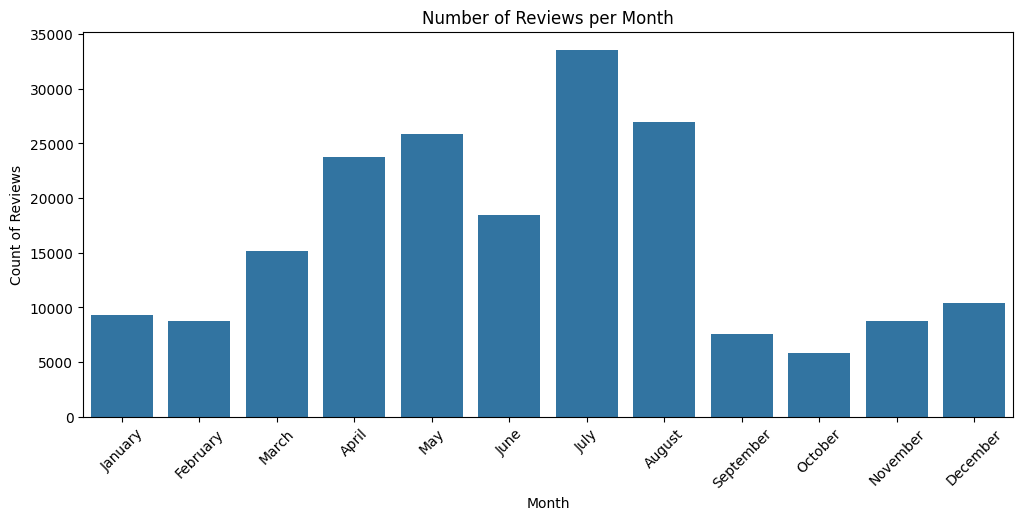

In [22]:
plt.figure(figsize=(12,5))

sns.countplot(data=df, x='month', order=[
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
])

plt.title('Number of Reviews per Month')
plt.xlabel('Month')
plt.ylabel('Count of Reviews')
plt.xticks(rotation=45)
plt.show()

In [30]:
# Creating categorical Variable from Numerical Reviews.

conditions = [
    df['Ratings'].isin([1, 2]),
    df['Ratings'] == 3,
    df['Ratings'].isin([4, 5])
]

categories = ['Bad', 'OK', 'Very Good']

df['review_category'] = np.select(conditions, categories,default = 'Unknown')
df.head(10)

,Review Id,Review,Ratings,Review Date,month,review_category
0,6fb93778-651a-4ad1-b5ed-67dd0bd35aac,good,5,2024-08-23 19:30:05,August,Very Good
1,81caeefd-3a28-4601-a898-72897ac906f5,good,5,2024-08-23 19:28:18,August,Very Good
2,452af49e-1d8b-4b68-b1ac-a94c64cb1dd5,nice app,5,2024-08-23 19:22:59,August,Very Good
3,372a4096-ee6a-4b94-b046-cef0b646c965,"nice, ig",5,2024-08-23 19:20:50,August,Very Good
4,b0d66a4b-9bde-4b7c-8b11-66ed6ccdd7da,"this is a great app, the bot is so accurate to...",5,2024-08-23 19:20:39,August,Very Good
5,9cdc3f78-15cd-4e9d-9287-31bc5af496c4,so nice app,5,2024-08-23 19:18:35,August,Very Good
6,3c26ee92-4d72-45ee-9242-caab930903ca,"just love this app, or guy",4,2024-08-23 19:14:40,August,Very Good
7,f293ed19-688a-42e2-8282-ddd077771a94,great app,1,2024-08-23 19:12:00,August,Bad
8,99af016c-6db2-4f24-9952-cb3bece40be8,Very impressive,5,2024-08-23 19:11:46,August,Very Good
9,27dd6ea5-ada3-4795-a297-6faa7d4b6ba2,helps with coding a lot this ai is great for e...,5,2024-08-23 19:11:09,August,Very Good


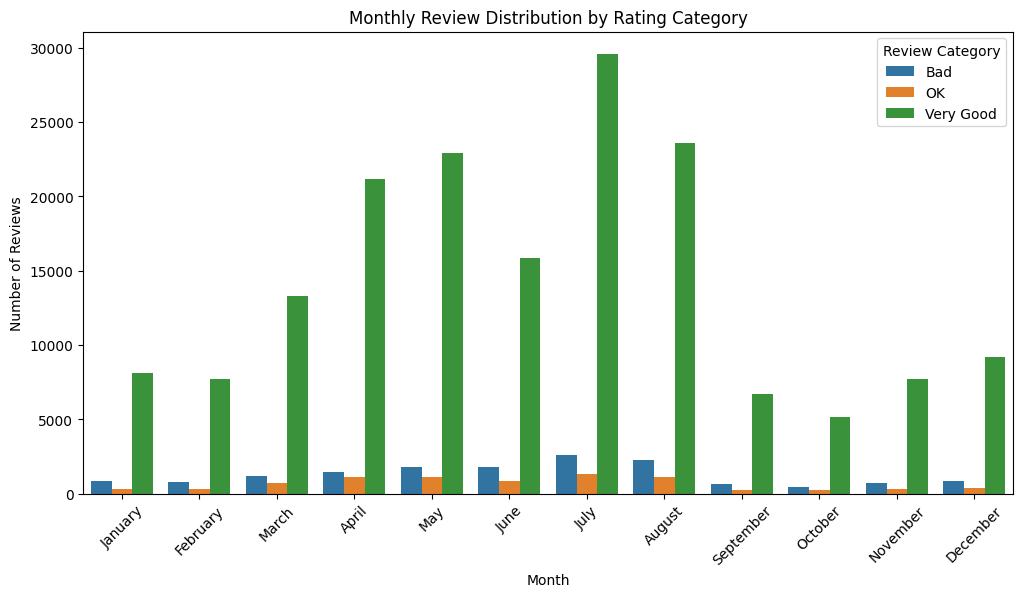

In [31]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x='month',
    hue='review_category',
    order=[
        'January', 'February', 'March', 'April',
        'May', 'June', 'July', 'August',
        'September', 'October', 'November', 'December'
    ],
    hue_order=['Bad', 'OK', 'Very Good']
)

plt.title('Monthly Review Distribution by Rating Category')
plt.xlabel('Month')
plt.ylabel('Number of Reviews')
plt.legend(title='Review Category')
plt.xticks(rotation=45)

plt.show()